# 14 — Strategic bidding: one firm, one day (Part 3, Stage 3)

**Does:** finds one firm's most profitable strategy on a day while every other firm bids its true cost, and measures what it does to prices, consumers and costs.

**Input:** the Part 1 market (`LossDispatchModel`), Part 2's weather-based availability (`availability_daily.csv`), firms and roles (Stage 0), bids and withholding (Stage 2), RSI and tightness (Stage 1: `market_structure_*_daily.csv`)

**Plan:** `docs/part3_plan.md`, Stage 3. **Logged in:** `docs/model_log.md`, Step 24.

## Method: `best_response()` in `src/bidding.py`

A firm chooses an **adder** (its strategic blocks bid cost + adder + 1, at most Rs 8,990) and a **withholding share** (0–30% of its strategic capacity). For each strategy tried, the LP is re-run and the firm's profit measured at true cost.

| Step | What | Decision |
|---|---|---|
| Bid candidates | Rs 1 below every other block's bid level (a price-setting firm's profit rises until it passes a rival), the cap, and a regular grid every Rs 250 as a safety net | 1: rival levels + grid |
| Coarse search | Every candidate × withholding 0, 10, 20, 30% | 2: joint, coarse then fine |
| Fine search | Around the best: adders every Rs 25 (± 250), withholding ± 5% | 2 |

Bidding cost (adder 0, withholding 0) is always tried, so the best strategy never earns less than bidding cost.

**Days (decision 3):** UP, the largest firm, on four kinds of day.

**Hypotheses, written before running:**

| Day | Expected best strategy |
|---|---|
| Pivotal (UP's lowest RSI) | At or near the cap |
| Near a coal-tier step, UP not pivotal | A small markup, about one coal tier |
| Ordinary (median spare, not near a step) | Little or none |
| Slack (most spare) | None: bidding cost is best |

Also: raising the bid beats withholding on pivotal days; the joint search rarely beats the best single family.

In [1]:
import sys
sys.path.insert(0, "../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dispatch import (LossDispatchModel, load_generators, load_demand, load_coordinates, loss_matrix,
                      daily_availability_lookup, VOLL)
from bidding import (firm_blocks, best_response, bid_candidates, make_bids, firm_profit,
                     consumer_cost, MAX_BID)

gen = load_generators()
blocks = firm_blocks(gen)
demand = load_demand()
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)

daily = pd.read_csv("../data/processed/availability_daily.csv", parse_dates=["Date"])
structure = pd.read_csv("../data/processed/market_structure_daily.csv", parse_dates=["Date"])
national = pd.read_csv("../data/processed/market_structure_national_daily.csv", parse_dates=["Date"]).set_index("Date")
print(f"Max bid Rs {MAX_BID:,.0f}; VOLL Rs {VOLL:,.0f}")

Max bid Rs 8,990; VOLL Rs 10,000


## 3.1 Toy cases, solved by hand first

1. **Pivotal** (the plan's example): A owns 80 MW at Rs 1,000; the rest is 50 MW at Rs 2,000; demand 100. The rest can't cover demand, so A should bid the **cap**: profit (8,990 − 1,000) × 50 = **399,500**
2. **Not pivotal:** A owns 80 MW at Rs 1,000; a rival owns 100 MW at Rs 3,000; demand 70. The rival alone could cover demand, so A can't bid the cap; A can cover demand alone, so it sets the price while it undercuts. Best: bid **2,999**, profit 1,999 × 70 = **139,930**

In [2]:
toy_loss = pd.DataFrame([[np.nan, 0.0], [0.0, np.nan]], index=["A", "B"], columns=["A", "B"])
toy_avail = {"Coal": 1.0, "Nuclear": 1.0}

def toy(rival_mw, rival_cost, demand_a):
    g = pd.DataFrame({"State": ["A", "B"], "Fuel_Type": ["Coal", "Nuclear"],
                      "Capacity_MW": [80.0, rival_mw], "Marginal_Cost_Rs_per_MWh": [1000.0, rival_cost],
                      "Available_MW": [80.0, rival_mw]})
    m, b = LossDispatchModel(g, toy_loss, ["A", "B"]), firm_blocks(g)
    br = best_response(m, b, "A", pd.Series({"A": demand_a, "B": 0.0}), toy_avail)
    return br, br["best"]["states"].loc["A", "Price"]

for name, args, expected in [("Pivotal", (50.0, 2000.0, 100.0), 399_500),
                             ("Not pivotal", (100.0, 3000.0, 70.0), 139_930)]:
    br, price = toy(*args)
    print(f"{name}: best adder {br['adder']}, price {price:,.0f}, profit {br['profit']:,.0f} "
          f"(hand: {expected:,}), at cost {br['profit_at_cost']:,.0f}")
    assert abs(br["profit"] - expected) < 1e-6

Pivotal: best adder 7989, price 8,990, profit 399,500 (hand: 399,500), at cost 80,000


Not pivotal: best adder 1998, price 2,999, profit 139,930 (hand: 139,930), at cost 0


## 3.2 UP on four days

Day rules (decision 3): **pivotal** = UP's lowest RSI; **near-step** = 10–20% spare, near-step flag on, UP not pivotal, tightest such day; **ordinary** = median spare among days not near a step; **slack** = most spare.

In [3]:
up_rsi = structure[structure["Firm"] == "NR UP"].set_index("Date")["RSI"]
nat = national.assign(UP_RSI=up_rsi)

near = nat[nat["Near_step"] & nat["Tightness"].between(0.10, 0.20) & (nat["UP_RSI"] >= 1)]
plain = nat[~nat["Near_step"]]
DAYS = {
    "Pivotal": up_rsi.idxmin(),
    "Near-step": near.sort_values(["Tightness", "UP_RSI"]).index[0],
    "Ordinary": (plain["Tightness"] - plain["Tightness"].median()).abs().idxmin(),
    "Slack": nat["Tightness"].idxmax(),
}
lookup = daily_availability_lookup(daily[daily["Date"].isin(list(DAYS.values()))])

pd.DataFrame({k: {"Date": d.date(), "Spare %": round(100 * nat.loc[d, "Tightness"], 1),
                  "UP RSI": round(nat.loc[d, "UP_RSI"], 3), "Near step": bool(nat.loc[d, "Near_step"]),
                  "Pivotal firms": int(nat.loc[d, "Pivotal_firms"])} for k, d in DAYS.items()}).T

,Date,Spare %,UP RSI,Near step,Pivotal firms
Pivotal,2025-01-30,5.0,0.939,True,9
Near-step,2025-02-06,12.0,1.012,True,0
Ordinary,2024-03-17,23.0,1.109,False,0
Slack,2024-08-25,53.0,1.397,False,0


In [4]:
results, timing = {}, {}
for kind, d in DAYS.items():
    t0 = time.time()
    results[kind] = best_response(model, blocks, "NR UP", demand.loc[d], lookup[d])
    timing[kind] = time.time() - t0

def summary(br):
    best, cost = br["best"], br["at_cost"]
    s_b, s_c = best["states"], cost["states"]
    w_price = lambda s: np.average(s["Price"], weights=s["Demand_MW"])
    return {
        "Best adder": br["adder"], "Withholding": f"{br['withholding']:.0%}",
        "UP bid (coal)": best["generation"].set_index(["State", "Fuel_Type"]).loc[("NR UP", "Coal"), "Bid"],
        "UP profit at cost (Rs lakh/h)": br["profit_at_cost"] / 1e5,
        "UP profit best (Rs lakh/h)": br["profit"] / 1e5,
        "Avg price at cost": w_price(s_c), "Avg price best": w_price(s_b),
        "Consumer cost change %": 100 * (consumer_cost(best) / consumer_cost(cost) - 1),
        "Consumer cost change (Rs crore/h)": (consumer_cost(best) - consumer_cost(cost)) / 1e7,
        "Generation cost change %": 100 * ((best["generation"]["Marginal_Cost_Rs_per_MWh"] * best["generation"]["Dispatch_MW"]).sum()
                                            / (cost["generation"]["Marginal_Cost_Rs_per_MWh"] * cost["generation"]["Dispatch_MW"]).sum() - 1),
        "UP output change (GW)": (best["generation"].query("State == 'NR UP'")["Dispatch_MW"].sum()
                                  - cost["generation"].query("State == 'NR UP'")["Dispatch_MW"].sum()) / 1000,
        "Unserved MW": s_b["Unserved_MW"].sum(),
    }

table = pd.DataFrame({k: summary(br) for k, br in results.items()})
table.round(1)

,Pivotal,Near-step,Ordinary,Slack
Best adder,6775,1500,1098,500
Withholding,0%,0%,0%,0%
UP bid (coal),8976.0,3701.0,3299.0,2701.0
UP profit at cost (Rs lakh/h),411.303988,362.214325,170.360953,44.256338
UP profit best (Rs lakh/h),1218.107293,402.576366,231.895824,89.037253
Avg price at cost,3766.35014,3567.701374,2793.684114,2200.281986
Avg price best,9001.636911,3750.957139,3379.355287,2672.680855
Consumer cost change %,139.001595,5.136522,20.964116,21.469924
Consumer cost change (Rs crore/h),123.840709,4.316113,12.277132,9.615396
Generation cost change %,3.802442,0.206752,1.415725,0.634356


### Profit against the bid

UP's profit (no withholding) as its adder rises, on each day. Dots mark the best strategy found.

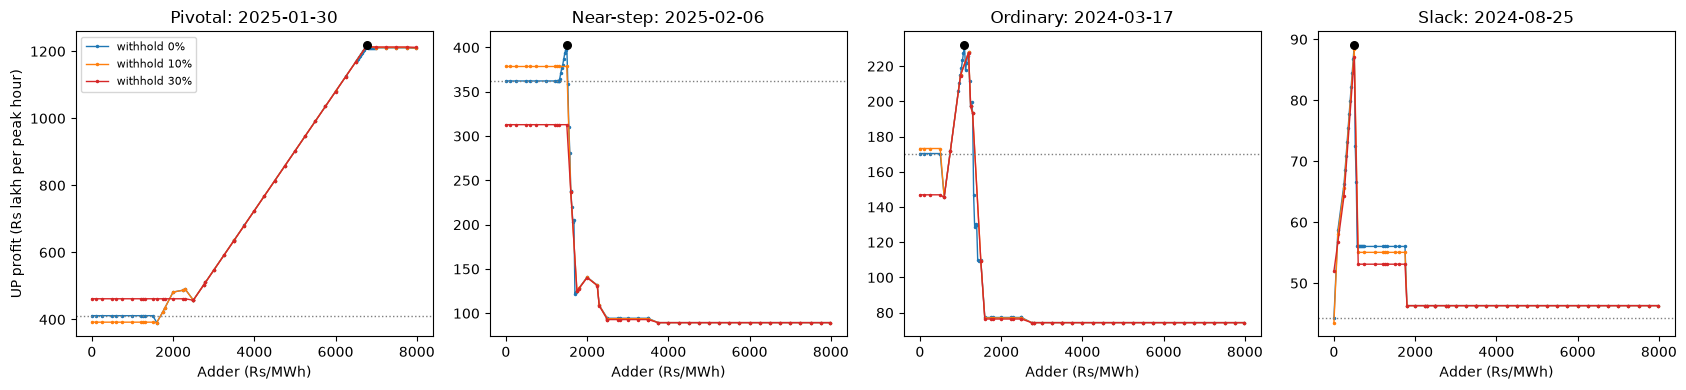

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=False)
for ax, (kind, br) in zip(axes, results.items()):
    t = br["table"]
    for w, color in [(0.0, "tab:blue"), (0.1, "tab:orange"), (0.3, "tab:red")]:
        sub = t[np.isclose(t["Withholding"], w)].sort_values("Adder")
        ax.plot(sub["Adder"], sub["Profit"] / 1e5, marker=".", markersize=3, linewidth=1, color=color,
                label=f"withhold {w:.0%}")
    ax.scatter([br["adder"]], [br["profit"] / 1e5], color="black", zorder=5, s=30)
    ax.axhline(br["profit_at_cost"] / 1e5, color="tab:gray", linestyle=":", linewidth=1)
    ax.set_title(f"{kind}: {DAYS[kind].date()}")
    ax.set_xlabel("Adder (Rs/MWh)")
axes[0].set_ylabel("UP profit (Rs lakh per peak hour)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Where prices move (pivotal day)

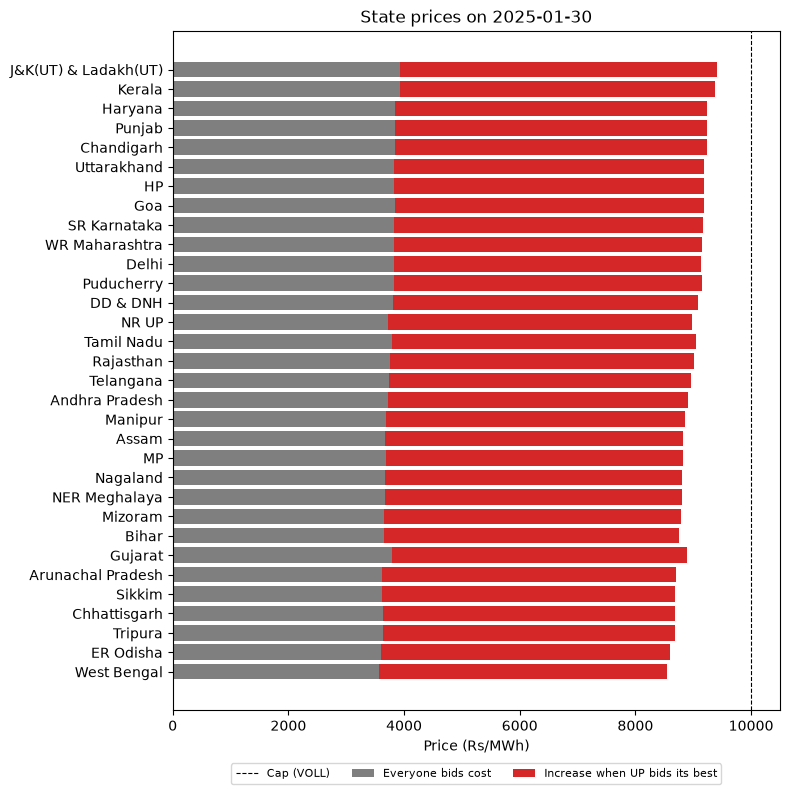

In [6]:
kind = "Pivotal"
s_c, s_b = results[kind]["at_cost"]["states"], results[kind]["best"]["states"]
move = pd.DataFrame({"At cost": s_c["Price"], "UP best": s_b["Price"]})
move["Change"] = move["UP best"] - move["At cost"]
move = move.sort_values("Change")

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(move.index, move["At cost"], color="tab:gray", label="Everyone bids cost")
ax.barh(move.index, move["Change"], left=move["At cost"], color="tab:red", label="Increase when UP bids its best")
ax.axvline(VOLL, color="black", linestyle="--", linewidth=0.8, label="Cap (VOLL)")
ax.set_xlabel("Price (Rs/MWh)")
ax.set_title(f"State prices on {DAYS[kind].date()}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

## 3.3 Raise the bid or withhold?

For each day, the most profitable strategy of each family: **bid only** (withholding 0), **withhold only** (adder 0), **both** (the overall best).

In [7]:
rows = {}
for kind, br in results.items():
    t = br["table"]
    bid_only = t[np.isclose(t["Withholding"], 0)].sort_values("Profit").iloc[-1]
    hold_only = t[t["Adder"] == 0].sort_values("Profit").iloc[-1]
    rows[kind] = {
        "Bid only: adder": bid_only["Adder"], "Bid only: profit": bid_only["Profit"] / 1e5,
        "Withhold only: share": f"{hold_only['Withholding']:.0%}", "Withhold only: profit": hold_only["Profit"] / 1e5,
        "Both: profit": br["profit"] / 1e5,
        "Joint gain over best single (%)": 100 * (br["profit"] / max(bid_only["Profit"], hold_only["Profit"]) - 1),
    }
pd.DataFrame(rows).T.round(1)

,Bid only: adder,Bid only: profit,Withhold only: share,Withhold only: profit,Both: profit,Joint gain over best single (%)
Pivotal,6775.0,1218.107293,20%,486.03147,1218.107293,0.0
Near-step,1500.0,402.576366,10%,378.544453,402.576366,0.0
Ordinary,1098.0,231.895824,10%,173.222266,231.895824,0.0
Slack,500.0,89.037253,30%,51.990333,89.037253,0.0


## 3.4 Timing

In [8]:
per_search = np.mean(list(timing.values()))
n_tried = np.mean([len(br["table"]) for br in results.values()])
print(f"One best response: {per_search:.2f} s on average ({n_tried:.0f} strategies, "
      f"{1000 * per_search / n_tried:.1f} ms per market run); {len(bid_candidates(blocks, 'NR UP'))} adder candidates for UP")

players_1gw = (blocks[blocks["Role"] == "strategic"].groupby("Firm")["Capacity_MW"].sum() >= 1000).sum()
for label, searches in [("Stage 4: UP alone, 396 days", 396),
                        ("Stage 4: each of the 9 pivotal firms alone, 396 days", 9 * 396),
                        (f"Stage 5: {players_1gw} firms ≥ 1 GW, 1 round, 396 days", players_1gw * 396),
                        (f"Stage 5: {players_1gw} firms, 5 rounds, 60-day sample", players_1gw * 5 * 60),
                        (f"Stage 5: {players_1gw} firms, 5 rounds, 396 days", players_1gw * 5 * 396)]:
    print(f"  {label}: {searches * per_search / 60:,.0f} min")

One best response: 1.34 s on average (211 strategies, 6.3 ms per market run); 43 adder candidates for UP
  Stage 4: UP alone, 396 days: 9 min
  Stage 4: each of the 9 pivotal firms alone, 396 days: 79 min
  Stage 5: 24 firms ≥ 1 GW, 1 round, 396 days: 212 min
  Stage 5: 24 firms, 5 rounds, 60-day sample: 160 min
  Stage 5: 24 firms, 5 rounds, 396 days: 1,058 min


## Stage 3 conclusions

| Day | Spare | Best strategy for UP | UP profit | Consumers pay | Hypothesis |
|---|---|---|---|---|---|
| **Pivotal** (30 Jan 2025) | 5% | Coal bid **8,976**, near the cap | **3.0×** (411 → 1,218 lakh/h) | **+139%** (+Rs 124 crore/h) | ✅ at or near the cap |
| **Near-step** (6 Feb 2025) | 12% | Coal bid **3,701**: about one tier up, just under coastal coal (3,800) | +11% | +5% | ✅ about one tier |
| **Ordinary** (17 Mar 2024) | 23% | Coal bid **3,299** | +36% | **+21%** | ❌ expected little |
| **Slack** (25 Aug 2024) | 53% | Coal bid **2,701**: just under inland coal (2,800) | **2.0×** (44 → 89 lakh/h) | **+21%** | ❌ expected none |

**1. Market power doesn't need a tight market.** Even on the slackest day of the year, UP doubles its profit by bidding just below the next coal tier. Spare capacity isn't the same as *cheap* spare capacity: on 25 Aug the 53% spare is mostly expensive plant (inland and coastal coal, gas). When UP prices its coal up to just under the next tier, the cheaper rivals are already running flat out, so UP still sets the price. **The RSI (Stage 1) misses this:** it counts all spare capacity at any cost. A **stepped supply curve gives the marginal firm room up to the next step on almost any day.**

**2. Consumers lose far more than UP gains.** On the slack day UP gains Rs 0.45 crore/h, but consumers pay Rs 9.6 crore/h more: every other plant that runs is also paid the higher price. Market power is mostly a **transfer to all generators**, triggered by one.

**3. Raising the bid always beats withholding** on all four days, and the joint search never improves on the best single family (gain 0%). Withholding throws away output that would earn the higher price; bidding high lets the market decide what to drop. Withholding alone still pays on every day (by 2–18%), so a firm barred from raising its bid would withhold instead (Stage 7's must-offer what-if).

**4. Efficiency loss is small** (true generation cost +0.2% to +3.8%): the expensive plants that replace UP aren't much costlier. The harm is in **prices, not wasted fuel**.

**5. The safety-net grid matters.** On the near-step day the best bid (3,701) came from the regular grid, not from "Rs 1 below a rival" (3,799). With losses, what UP must undercut is a rival's price *where UP's power lands*, which sits between the round levels.

**Caveat, important for reading all of Part 3:** "UP" is one firm owning all 32.7 GW of strategic capacity in the state (one firm per state, plan decision 2). In reality that capacity is split between NTPC, the state utility and private owners, so these markups are an **upper bound**. Splitting the largest firm is a Stage 7 what-if.

**Timing:** one search takes **1.3 s** (211 strategies, 6 ms per market run). Stage 4 (9 firms × 396 days) needs ~76 min; Stage 5 with all 24 firms ≥ 1 GW and 5 rounds would take ~17 hours on 396 days, or ~2.5 hours on the plan's 60-day sample.